# Notebook 3 — Data Preprocessing
## Proyek Mandiri: Deteksi Pencemaran Limbah pada Sungai Berbasis IoT dan Artificial Intelligence

Notebook ini menyiapkan dataset untuk tahap **pemodelan deteksi dan klasifikasi**, bukan prediksi kondisi air di masa mendatang. Fitur eksperimen disesuaikan dengan perangkat IoT yang dirancang: suhu (`temp_C`), pH (`pH`), dan kekeruhan (`turbidity_NTU`). Target klasifikasi menggunakan kolom `class` jika tersedia.

### Keputusan preprocessing yang digunakan
- Data mentah disimpan pada `df_raw`; perubahan dilakukan pada salinan kerja.
- Baris duplikat penuh dihapus karena tidak menambah observasi baru.
- Nilai tak hingga diubah menjadi nilai kosong.
- Nilai yang secara fisik tidak masuk akal untuk fitur sensor terpilih (suhu negatif, pH di luar 0–14, atau kekeruhan negatif) diperlakukan sebagai nilai tidak valid dan tidak digunakan dalam dataset eksperimen.
- **Outlier statistik berdasarkan IQR tidak otomatis dihapus atau di-cap.** Nilai ekstrem dapat merupakan kejadian lingkungan yang penting. Outlier ditampilkan melalui tabel dan grafik agar keputusan tidak menghilangkan sinyal deteksi anomali.
- Baris yang masih memiliki nilai kosong pada fitur eksperimen atau target tidak dimasukkan ke dataset eksperimen. Tidak dilakukan imputasi global; scaling dan transformasi yang dipelajari dari data dilakukan di notebook pemodelan setelah train-test split.
- Hasil disimpan sebagai `dataset_setelah_pemeriksaan.csv` dan `dataset_eksperimen_sensor.csv`.

> **Batas interpretasi:** nama dataset yang digunakan pada eksperimen awal mengindikasikan konteks fishpond/kolam. Karena itu, hasil model dari dataset ini merupakan hasil eksperimen awal dan tidak boleh langsung dianggap sebagai bukti deteksi pencemaran sungai di lapangan. Status kelas juga mengikuti label yang tersedia pada dataset, bukan hasil konfirmasi laboratorium oleh proyek ini.

## Tahap 1 — Memuat Dataset
**Tujuan:** membaca CSV dan mempertahankan salinan data asli. Unggah file dataset yang digunakan untuk eksperimen.

In [1]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

try:
    from google.colab import files
    uploaded = files.upload()
    if not uploaded:
        raise ValueError("Belum ada file CSV yang diunggah. Jalankan ulang sel ini dan pilih dataset.")
    filename = next(iter(uploaded))
    df_raw = pd.read_csv(io.BytesIO(uploaded[filename]))
except ImportError:
    filename = "fishpond_dataset_multiclass_2153.csv"  # sesuaikan bila menjalankan lokal
    df_raw = pd.read_csv(filename)

df_raw.columns = [str(c).strip() for c in df_raw.columns]
df = df_raw.copy(deep=True)
print("File sumber:", filename)
print("Ukuran awal:", df.shape[0], "baris ×", df.shape[1], "kolom")
display(df.head())

Saving fishpond_dataset_multiclass_2153.csv to fishpond_dataset_multiclass_2153.csv
File sumber: fishpond_dataset_multiclass_2153.csv
Ukuran awal: 2153 baris × 10 kolom


,sample_id,timestamp,orp_mV,ec_uScm,tds_mgL,turbidity_NTU,temp_C,pH,do_mgL,class
0,1507,2026-01-06 05:30:00,594.66,19.14,6.07,130.13,21.86,9.35,11.69,Warning
1,1768,2026-01-07 03:15:00,593.54,1831.09,1017.97,52.15,20.17,9.32,2.33,Warning
2,890,2026-01-04 02:05:00,495.26,40.52,29.74,35.69,30.10,6.49,9.09,Caution
3,307,2026-01-02 01:30:00,281.85,442.84,221.24,17.30,25.51,7.71,6.09,Normal
4,1774,2026-01-07 03:45:00,510.28,1790.43,859.00,132.55,32.56,5.62,2.82,Warning


## Tahap 2 — Memahami Struktur Dataset
**Tujuan:** mengetahui kolom, tipe data, dan ringkasan awal. Tahap ini membantu memastikan kolom yang dipakai pada eksperimen memang tersedia.

In [2]:
print("Jumlah baris:", len(df))
print("Jumlah kolom:", len(df.columns))
print("Nama kolom:", df.columns.tolist())
display(pd.DataFrame({"tipe_data": df.dtypes.astype(str), "jumlah_kosong": df.isna().sum()}))
display(df.head(5))
display(df.describe(include="all").T)

Jumlah baris: 2153
Jumlah kolom: 10
Nama kolom: ['sample_id', 'timestamp', 'orp_mV', 'ec_uScm', 'tds_mgL', 'turbidity_NTU', 'temp_C', 'pH', 'do_mgL', 'class']


,tipe_data,jumlah_kosong
sample_id,int64,0
timestamp,object,0
orp_mV,float64,0
ec_uScm,float64,0
tds_mgL,float64,0
turbidity_NTU,float64,0
temp_C,float64,0
pH,float64,0
do_mgL,float64,0
class,object,0


,sample_id,timestamp,orp_mV,ec_uScm,tds_mgL,turbidity_NTU,temp_C,pH,do_mgL,class
0,1507,2026-01-06 05:30:00,594.66,19.14,6.07,130.13,21.86,9.35,11.69,Warning
1,1768,2026-01-07 03:15:00,593.54,1831.09,1017.97,52.15,20.17,9.32,2.33,Warning
2,890,2026-01-04 02:05:00,495.26,40.52,29.74,35.69,30.10,6.49,9.09,Caution
3,307,2026-01-02 01:30:00,281.85,442.84,221.24,17.30,25.51,7.71,6.09,Normal
4,1774,2026-01-07 03:45:00,510.28,1790.43,859.00,132.55,32.56,5.62,2.82,Warning


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
sample_id,2153.0,NaN,NaN,NaN,1077.0,621.661886,1.0,539.0,1077.0,1615.0,2153.0
timestamp,2153,2153,2026-01-03 23:40:00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
orp_mV,2153.0,NaN,NaN,NaN,291.254426,261.019449,-249.6,85.45,287.24,471.09,898.88
ec_uScm,2153.0,NaN,NaN,NaN,655.755727,1025.007425,1.04,30.06,244.55,783.26,4965.58
tds_mgL,2153.0,NaN,NaN,NaN,359.809039,563.781797,0.0,16.67,127.57,422.4,3267.23
turbidity_NTU,2153.0,NaN,NaN,NaN,101.352982,138.438025,1.02,21.41,41.48,113.93,598.68
temp_C,2153.0,NaN,NaN,NaN,27.436512,5.193092,15.0,23.85,27.53,31.41,37.99
pH,2153.0,NaN,NaN,NaN,7.55602,1.542629,4.51,6.21,7.57,8.89,10.5
do_mgL,2153.0,NaN,NaN,NaN,7.087938,3.600887,0.52,4.32,6.94,9.58,15.98
class,2153,4,Caution,670,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Tahap 3 — Menangani Baris Duplikat
**Keputusan:** baris yang identik pada seluruh kolom dihapus. Nilai sensor yang kebetulan sama pada waktu berbeda tidak dianggap duplikat kecuali seluruh isi barisnya sama.

In [3]:
jumlah_awal = len(df)
jumlah_duplikat = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Baris awal:", jumlah_awal)
print("Baris duplikat penuh dihapus:", jumlah_duplikat)
print("Baris setelah penghapusan duplikat:", len(df))

Baris awal: 2153
Baris duplikat penuh dihapus: 0
Baris setelah penghapusan duplikat: 2153


## Tahap 4 — Menangani Missing Values
**Keputusan:** nilai kosong dilaporkan pada seluruh kolom. Untuk dataset eksperimen, baris yang masih kosong pada fitur sensor atau target akan dikeluarkan pada Tahap 10. Tidak dilakukan imputasi menggunakan seluruh dataset agar tidak mencampurkan informasi data uji ke proses pelatihan.

,jumlah_kosong,persentase_kosong_%
sample_id,0,0.0
timestamp,0,0.0
orp_mV,0,0.0
ec_uScm,0,0.0
tds_mgL,0,0.0
turbidity_NTU,0,0.0
temp_C,0,0.0
pH,0,0.0
do_mgL,0,0.0
class,0,0.0


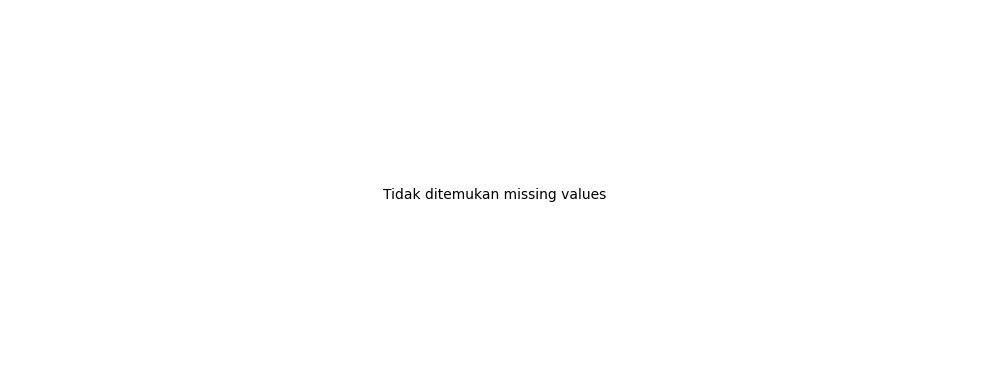

In [4]:
missing_report = pd.DataFrame({
    "jumlah_kosong": df.isna().sum(),
    "persentase_kosong_%": (df.isna().mean() * 100).round(3)
}).sort_values("jumlah_kosong", ascending=False)
display(missing_report)

plt.figure(figsize=(10, 4))
missing_plot = missing_report[missing_report["jumlah_kosong"] > 0]
if not missing_plot.empty:
    plt.bar(missing_plot.index.astype(str), missing_plot["persentase_kosong_%"])
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("Nilai kosong (%)")
    plt.title("Persentase Missing Values per Kolom")
else:
    plt.text(0.5, 0.5, "Tidak ditemukan missing values", ha="center", va="center")
    plt.axis("off")
plt.tight_layout()
plt.show()

## Tahap 5 — Menyiapkan Timestamp (Jika Tersedia)
**Tujuan:** mengubah kolom waktu menjadi format datetime dan menambahkan kolom bantu `timestamp_parsed`. Kolom waktu digunakan untuk dokumentasi dan memahami urutan data; tidak dimasukkan sebagai fitur model deteksi pada tahap ini.

In [5]:
timestamp_candidates = [c for c in df.columns if c.lower() in ["timestamp", "datetime", "date_time", "time"]]
if timestamp_candidates:
    timestamp_col = timestamp_candidates[0]
    df["timestamp_parsed"] = pd.to_datetime(df[timestamp_col], errors="coerce")
    valid_times = df["timestamp_parsed"].dropna()
    print("Kolom waktu:", timestamp_col)
    print("Timestamp yang gagal dibaca:", int(df["timestamp_parsed"].isna().sum()))
    if not valid_times.empty:
        print("Waktu awal:", valid_times.min())
        print("Waktu akhir:", valid_times.max())
        print("Jumlah timestamp valid:", len(valid_times))
else:
    timestamp_col = None
    print("Dataset tidak memiliki kolom timestamp yang dikenali; tahap waktu dilewati.")

Kolom waktu: timestamp
Timestamp yang gagal dibaca: 0
Waktu awal: 2026-01-01 00:00:00
Waktu akhir: 2026-01-08 11:20:00
Jumlah timestamp valid: 2153


## Tahap 6 — Menangani Nilai Tidak Valid
**Keputusan:** nilai `inf` dan `-inf` diubah menjadi `NaN`. Untuk fitur sensor yang digunakan pada eksperimen, nilai yang secara fisik tidak masuk akal ditandai sebagai kosong: suhu di bawah 0 °C, pH di luar 0–14, dan kekeruhan di bawah 0 NTU. Nilai ini tidak diisi dengan angka buatan; baris yang tidak valid pada fitur terpilih tidak akan masuk ke dataset eksperimen.

In [6]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
if numeric_cols:
    inf_counts = {c: int(np.isinf(pd.to_numeric(df[c], errors="coerce")).sum()) for c in numeric_cols}
    print("Nilai tak hingga per kolom:")
    display(pd.Series(inf_counts, name="jumlah_inf").to_frame())
    df[numeric_cols] = df[numeric_cols].replace([np.inf, -np.inf], np.nan)

invalid_counts = {}
if "temp_C" in df.columns:
    mask = pd.to_numeric(df["temp_C"], errors="coerce") < 0
    invalid_counts["temp_C < 0°C"] = int(mask.sum())
    df.loc[mask, "temp_C"] = np.nan
if "pH" in df.columns:
    values = pd.to_numeric(df["pH"], errors="coerce")
    mask = (values < 0) | (values > 14)
    invalid_counts["pH di luar 0–14"] = int(mask.sum())
    df.loc[mask, "pH"] = np.nan
if "turbidity_NTU" in df.columns:
    mask = pd.to_numeric(df["turbidity_NTU"], errors="coerce") < 0
    invalid_counts["turbidity_NTU < 0"] = int(mask.sum())
    df.loc[mask, "turbidity_NTU"] = np.nan

display(pd.DataFrame({"aturan_nilai_tidak_valid": list(invalid_counts.keys()), "jumlah_ditandai_kosong": list(invalid_counts.values())}))
print("Catatan: rentang ini digunakan sebagai pemeriksaan dasar kewajaran angka, bukan sebagai ambang baku mutu sungai.")

Nilai tak hingga per kolom:


,jumlah_inf
sample_id,0
orp_mV,0
ec_uScm,0
tds_mgL,0
turbidity_NTU,0
temp_C,0
pH,0
do_mgL,0


,aturan_nilai_tidak_valid,jumlah_ditandai_kosong
0,temp_C < 0°C,0
1,pH di luar 0–14,0
2,turbidity_NTU < 0,0


Catatan: rentang ini digunakan sebagai pemeriksaan dasar kewajaran angka, bukan sebagai ambang baku mutu sungai.


## Tahap 7 — Identifikasi dan Penanganan Outlier
### Mengapa outlier tidak langsung dihapus?
Outlier IQR adalah **kandidat nilai ekstrem secara statistik**, bukan bukti bahwa data salah. Pada sistem deteksi pencemaran, perubahan ekstrem pada kekeruhan atau parameter lain justru dapat menjadi sinyal yang ingin dikenali. Menghapus semua outlier dapat menghilangkan contoh penting dan membuat model kurang peka terhadap kejadian tidak biasa.

### Keputusan final preprocessing
1. Gunakan metode IQR (`Q1 − 1,5 × IQR` dan `Q3 + 1,5 × IQR`) untuk menandai kandidat outlier pada fitur numerik.
2. Tampilkan jumlah, persentase, batas IQR, serta boxplot.
3. **Pertahankan kandidat outlier statistik** selama tidak melanggar aturan nilai tidak valid pada Tahap 6. Tidak dilakukan penghapusan, winsorization, atau clipping otomatis.
4. Pada tahap pemodelan, scaling (jika diperlukan) dilakukan setelah train-test split dan hanya di-fit pada data latih.

,kolom,Q1,Q3,IQR,batas_bawah,batas_atas,jumlah_kandidat,persentase_%
0,orp_mV,85.45,471.09,385.64,-493.010,1049.550,0,0.000
1,ec_uScm,30.06,783.26,753.20,-1099.740,1913.060,205,9.522
2,tds_mgL,16.67,422.40,405.73,-591.925,1030.995,214,9.940
3,turbidity_NTU,21.41,113.93,92.52,-117.370,252.710,280,13.005
4,temp_C,23.85,31.41,7.56,12.510,42.750,0,0.000
5,pH,6.21,8.89,2.68,2.190,12.910,0,0.000
6,do_mgL,4.32,9.58,5.26,-3.570,17.470,0,0.000


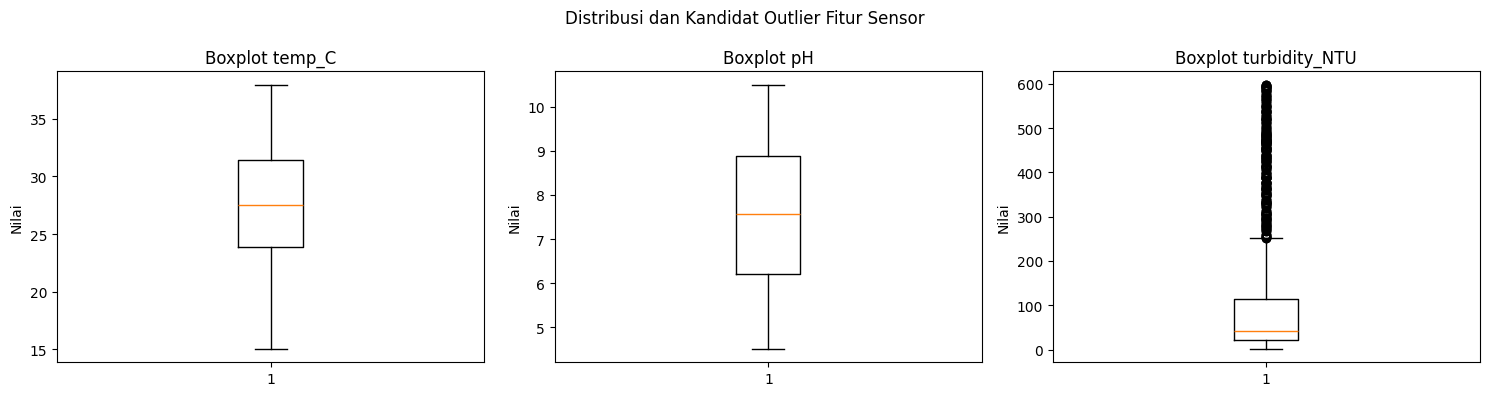

Keputusan: outlier statistik dipertahankan; hanya nilai tidak valid yang ditandai pada Tahap 6 yang dikeluarkan dari fitur eksperimen.


In [7]:
# Kolom identitas tidak dianalisis sebagai pengukuran sensor.
exclude_from_outlier = {"sample_id", "id"}
outlier_cols = [c for c in df.select_dtypes(include=np.number).columns if c.lower() not in exclude_from_outlier]
outlier_rows = []
for col in outlier_cols:
    s = pd.to_numeric(df[col], errors="coerce").dropna()
    if s.empty:
        continue
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (pd.to_numeric(df[col], errors="coerce") < lower) | (pd.to_numeric(df[col], errors="coerce") > upper)
    count = int(mask.sum())
    outlier_rows.append({"kolom": col, "Q1": q1, "Q3": q3, "IQR": iqr,
                         "batas_bawah": lower, "batas_atas": upper,
                         "jumlah_kandidat": count,
                         "persentase_%": round(count / max(len(s), 1) * 100, 3)})
outlier_report = pd.DataFrame(outlier_rows)
display(outlier_report.round(3))

plot_cols = [c for c in ["temp_C", "pH", "turbidity_NTU"] if c in df.columns]
if plot_cols:
    fig, axes = plt.subplots(1, len(plot_cols), figsize=(5 * len(plot_cols), 4))
    if len(plot_cols) == 1:
        axes = [axes]
    for ax, col in zip(axes, plot_cols):
        ax.boxplot(pd.to_numeric(df[col], errors="coerce").dropna(), vert=True)
        ax.set_title("Boxplot " + col)
        ax.set_ylabel("Nilai")
    fig.suptitle("Distribusi dan Kandidat Outlier Fitur Sensor")
    plt.tight_layout()
    plt.show()
else:
    print("Kolom sensor tidak ditemukan; boxplot fitur sensor dilewati.")
print("Keputusan: outlier statistik dipertahankan; hanya nilai tidak valid yang ditandai pada Tahap 6 yang dikeluarkan dari fitur eksperimen.")

## Tahap 8 — Korelasi dan Redundansi Fitur
**Tujuan:** melihat hubungan linear antarfitur numerik. Korelasi tinggi tidak otomatis membuat fitur dihapus; pemilihan fitur utama tetap mengikuti sensor yang benar-benar dipasang.

,orp_mV,ec_uScm,tds_mgL,turbidity_NTU,temp_C,pH,do_mgL
orp_mV,1.000,0.039,0.041,0.073,0.045,0.007,0.027
ec_uScm,0.039,1.000,0.990,0.489,0.010,0.011,0.048
tds_mgL,0.041,0.990,1.000,0.485,0.005,0.008,0.043
turbidity_NTU,0.073,0.489,0.485,1.000,-0.007,0.002,0.066
temp_C,0.045,0.010,0.005,-0.007,1.000,-0.017,0.030
pH,0.007,0.011,0.008,0.002,-0.017,1.000,-0.043
do_mgL,0.027,0.048,0.043,0.066,0.030,-0.043,1.000


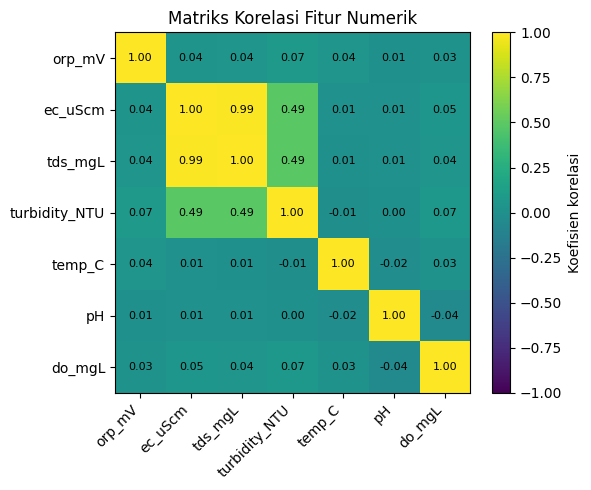

In [8]:
corr_cols = [c for c in df.select_dtypes(include=np.number).columns if c.lower() not in {"sample_id", "id"}]
if len(corr_cols) >= 2:
    corr = df[corr_cols].corr(numeric_only=True)
    display(corr.round(3))
    fig, ax = plt.subplots(figsize=(max(6, len(corr_cols) * 0.75), max(5, len(corr_cols) * 0.65)))
    im = ax.imshow(corr, vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(corr.index)), corr.index)
    for i in range(len(corr.index)):
        for j in range(len(corr.columns)):
            if pd.notna(corr.iloc[i, j]):
                ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title("Matriks Korelasi Fitur Numerik")
    fig.colorbar(im, ax=ax, label="Koefisien korelasi")
    plt.tight_layout()
    plt.show()
else:
    print("Kolom numerik tidak cukup untuk menghitung korelasi.")

## Tahap 9 — Ringkasan Distribusi Target
**Tujuan:** melihat jumlah dan proporsi tiap label yang tersedia untuk tugas klasifikasi. Tahap ini mendeskripsikan label dataset; tidak mengubah label dan tidak melatih model.

,jumlah,persentase_%
class,,
Caution,670,31.12
Normal,638,29.63
Warning,478,22.20
Severe,367,17.05


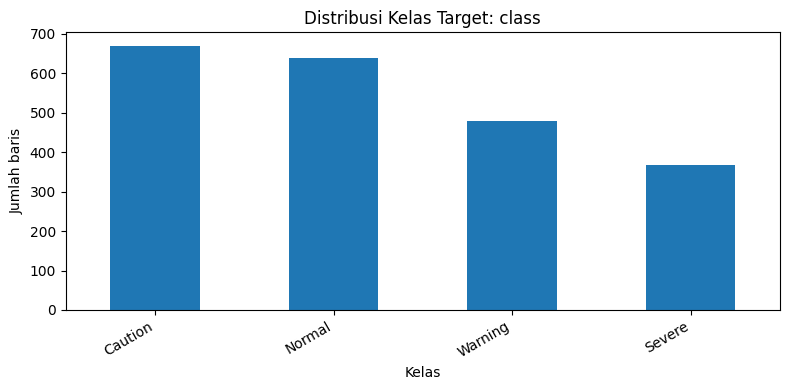

Label dipertahankan sesuai dataset sumber; notebook ini tidak membuat label baru.


In [9]:
target_candidates = ["class", "Pollution_Level", "label", "status"]
target_col = next((c for c in target_candidates if c in df.columns), None)
if target_col is None:
    print("Kolom target tidak ditemukan. Sesuaikan target_candidates dengan nama label pada dataset.")
else:
    counts = df[target_col].value_counts(dropna=False)
    target_report = pd.DataFrame({"jumlah": counts, "persentase_%": (counts / len(df) * 100).round(2)})
    display(target_report)
    plt.figure(figsize=(8, 4))
    counts.plot(kind="bar")
    plt.title("Distribusi Kelas Target: " + target_col)
    plt.xlabel("Kelas")
    plt.ylabel("Jumlah baris")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()
    print("Label dipertahankan sesuai dataset sumber; notebook ini tidak membuat label baru.")

## Tahap 10 — Seleksi Fitur Sesuai Sensor IoT
Fitur model utama ditetapkan sesuai rancangan perangkat:
- `temp_C`: suhu dari DS18B20 Waterproof.
- `pH`: tingkat keasaman dari PH-4502C.
- `turbidity_NTU`: kekeruhan dari Turbidity Sensor Module.

Kolom lain seperti EC, TDS, ORP, dan DO tidak digunakan sebagai input model utama karena tidak diukur oleh tiga sensor pada rancangan perangkat.

In [10]:
candidate_features = ["temp_C", "pH", "turbidity_NTU"]
available_features = [c for c in candidate_features if c in df.columns]
missing_features = [c for c in candidate_features if c not in df.columns]
print("Fitur yang digunakan:", available_features)
print("Fitur yang tidak tersedia:", missing_features)
if missing_features:
    raise ValueError("Kolom fitur sensor belum lengkap. Periksa nama kolom pada CSV sebelum melanjutkan.")
if target_col is None:
    raise ValueError("Kolom target tidak ditemukan. Sesuaikan target_candidates pada Tahap 9.")
print("Target klasifikasi:", target_col)

Fitur yang digunakan: ['temp_C', 'pH', 'turbidity_NTU']
Fitur yang tidak tersedia: []
Target klasifikasi: class


## Tahap 11 — Membentuk Dataset Eksperimen
**Keputusan:** tabel eksperimen hanya berisi tiga fitur sensor dan satu kolom target. Nilai `inf` sudah diubah menjadi kosong dan baris yang kosong pada fitur atau target dikeluarkan. Outlier statistik tetap dipertahankan. Belum dilakukan scaling maupun train-test split; keduanya dilakukan pada notebook pemodelan.

In [11]:
selected_cols = available_features + [target_col]
df_experiment = df[selected_cols].copy()
jumlah_sebelum = len(df_experiment)
df_experiment = df_experiment.replace([np.inf, -np.inf], np.nan)
df_experiment = df_experiment.dropna(subset=selected_cols).reset_index(drop=True)
X = df_experiment[available_features].copy()
y = df_experiment[target_col].copy()

print("Baris sebelum pembersihan kolom eksperimen:", jumlah_sebelum)
print("Baris dataset eksperimen:", len(df_experiment))
print("Baris yang dikeluarkan karena nilai kosong/tidak valid pada fitur atau target:", jumlah_sebelum - len(df_experiment))
print("Bentuk X:", X.shape)
print("Bentuk y:", y.shape)
print("Fitur X:", X.columns.tolist())
print("Target y:", y.name)
print("Missing values tersisa pada dataset eksperimen:", int(df_experiment.isna().sum().sum()))
display(df_experiment.head())
display(df_experiment.describe(include="all").T)

Baris sebelum pembersihan kolom eksperimen: 2153
Baris dataset eksperimen: 2153
Baris yang dikeluarkan karena nilai kosong/tidak valid pada fitur atau target: 0
Bentuk X: (2153, 3)
Bentuk y: (2153,)
Fitur X: ['temp_C', 'pH', 'turbidity_NTU']
Target y: class
Missing values tersisa pada dataset eksperimen: 0


,temp_C,pH,turbidity_NTU,class
0,21.86,9.35,130.13,Warning
1,20.17,9.32,52.15,Warning
2,30.10,6.49,35.69,Caution
3,25.51,7.71,17.30,Normal
4,32.56,5.62,132.55,Warning


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
temp_C,2153.0,NaN,NaN,NaN,27.436512,5.193092,15.0,23.85,27.53,31.41,37.99
pH,2153.0,NaN,NaN,NaN,7.55602,1.542629,4.51,6.21,7.57,8.89,10.5
turbidity_NTU,2153.0,NaN,NaN,NaN,101.352982,138.438025,1.02,21.41,41.48,113.93,598.68
class,2153,4,Caution,670,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Tahap 12 — Menyimpan Hasil Preprocessing
Dua file utama dihasilkan:
1. **`dataset_setelah_pemeriksaan.csv`** — dataset kerja yang sudah menghapus duplikasi penuh, menandai nilai sensor tidak valid sebagai kosong, dan memuat kolom bantu waktu jika tersedia.
2. **`dataset_eksperimen_sensor.csv`** — dataset final untuk notebook pemodelan, berisi `temp_C`, `pH`, `turbidity_NTU`, dan target.

File kedua merupakan keluaran final preprocessing untuk diteruskan ke tahap pemodelan deteksi/klasifikasi.

In [12]:
df.to_csv("dataset_setelah_pemeriksaan.csv", index=False)
df_experiment.to_csv("dataset_eksperimen_sensor.csv", index=False)
print("Berhasil menyimpan dataset_setelah_pemeriksaan.csv", df.shape)
print("Berhasil menyimpan dataset_eksperimen_sensor.csv", df_experiment.shape)

try:
    from google.colab import files
    files.download("dataset_setelah_pemeriksaan.csv")
    files.download("dataset_eksperimen_sensor.csv")
except ImportError:
    print("File tersimpan pada folder kerja notebook lokal.")

Berhasil menyimpan dataset_setelah_pemeriksaan.csv (2153, 11)
Berhasil menyimpan dataset_eksperimen_sensor.csv (2153, 4)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Kesimpulan Data Preprocessing
Tahap preprocessing menghasilkan dataset eksperimen yang selaras dengan perangkat IoT, menggunakan tiga fitur sensor (suhu, pH, dan kekeruhan) serta label dari dataset sumber. Baris duplikat penuh dihapus, nilai tak hingga ditangani, nilai sensor yang tidak masuk akal ditandai sebagai kosong, dan baris yang tidak lengkap pada fitur/target tidak disertakan dalam dataset eksperimen.

**Penanganan outlier:** kandidat outlier berdasarkan IQR dipertahankan jika tidak melanggar aturan nilai tidak valid. Keputusan ini menjaga kemungkinan sinyal kejadian ekstrem yang relevan bagi deteksi anomali.

**Tahap berikutnya — Notebook 4: Pemodelan AI/ML untuk deteksi dan klasifikasi.** Lakukan train-test split sebelum scaling atau transformasi yang mempelajari parameter dari data. Bandingkan model klasifikasi dan metode deteksi/clustering yang sesuai; jangan membangun model peramalan kondisi air di masa depan.

> **Batasan penggunaan:** model yang dilatih pada label dataset sumber hanya mempelajari pola yang direpresentasikan oleh label tersebut. Klaim deteksi pencemaran sungai nyata memerlukan pengujian tambahan dengan data sungai dan label rujukan yang sesuai.